In [1]:
import sys
sys.path.insert(1, 'CMAPSS')
import eval_utils
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import tensorflow as tf
from tensorflow import keras

from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt
from matplotlib import gridspec
import json
import os
import random
import warnings
from preProcessingData          import PreProcessData


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0"  


2024-10-15 17:11:11.014589: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-15 17:11:11.090720: I tensorflow/core/util/util.cc:169] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-10-15 17:11:11.109521: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-15 17:11:11.429870: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: li

In [2]:
with open('model/modelConfig.json', 'r') as configFile:
        config = json.load(configFile)
kanConfig = config["kan"]  

# ---------------------------------    
# Reactor, Separator,Stripper
# ---------------------------------
component  = kanConfig["component"]
modelName  = "kan"


os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'
# strategy = tf.distribute.MirroredStrategy()


np.random.seed(1)
random.seed(1)
# ---------------------------------
# Pre processing data
# ---------------------------------
preData                         = PreProcessData()
rawData                         = preData.loadCriticalData()                                            # Load the data from critical file
# addedVariablesData              = preData.additionEfficiencyVar(rawData)                                # Add some additional efficiency variable
normalizedAllData               = preData.normalizeBuilinFunction(rawData)                   # Normalize the all data
normalizedHealthy,healthyPos    = preData.getHealthyState(normalizedAllData)       # Load the healthy state
effTrajectories                 = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.beauEfficiencyCr1)         # Extract the trajectory
# circleTrajectories              = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= "tiempo")         # Extract the trajectory
maniTrajectories                = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.beauManipulatedCr1)         # Extract the trajectory


# ---------------------------------
# Create the cycles
# ---------------------------------
hours                           = preData.addFloatTime(rawData)
cycleTrajectories               = preData.getTrajectory(hours)         # Extract the trajectory


# print(maniTrajectories)
# ----------------------------------
# Split data to trajectories
# ----------------------------------
listOfEffData                      = []
for vlTraj in effTrajectories.values():
        listOfEffData = listOfEffData + vlTraj

listOfManiData                      = []
for vlTraj in maniTrajectories.values():
        listOfManiData = listOfManiData + vlTraj

# listOfCycleData                      = []
# for vlTraj in cycleTrajectories.values():
#         listOfCycleData = listOfCycleData + vlTraj

listOfCycleData = np.arange(0, 86479 * 0.1, 0.1)

# clearnData              = preData.cleanData(rawData[preData.crusher1Value])                     # Clean the data by using moving average
# norData                 = preData.normalizeBuilinFunction(clearnData[preData.crusher1Value])    # Normalize the data

# ---------------------------
# All data
# --------------------------
seqEffData,_     = preData.splitAllDataIntoSequences(listOfEffData)
seqManiData,_    = preData.splitAllDataIntoSequences(listOfManiData)
# seqCycleData,_   = preData.splitAllDataIntoSequences(listOfCycleData)
# seqCycleData     = np.expand_dims(seqCycleData, axis=-1)  # Adding a new axis at the last position
seqCycleData     = listOfCycleData
print(f"The size of the data: {seqEffData.shape} {seqManiData.shape} {seqCycleData.shape}")
print(type(seqEffData))

# ---------------------------
# Single sample
# ---------------------------
# singleTraject   = trajectory["Lubricación  deficiente"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
# seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap'])

# trajectory.keys()

Process:20606||2024-10-15 17:11:12,537-INFO [preProcessingData.py:loadCriticalData():220]:Loading critical MOF data from files ...
Process:20606||2024-10-15 17:11:12,892-INFO [preProcessingData.py:loadCriticalData():226]:Finish loading data from files ...
Process:20606||2024-10-15 17:11:14,090-INFO [preProcessingData.py:getHealthyState():536]:Getting critical trajectories ...
Process:20606||2024-10-15 17:11:15,562-INFO [preProcessingData.py:splitAllDataIntoSequences():665]:Spliting data into sequences now ...
Process:20606||2024-10-15 17:11:19,394-INFO [preProcessingData.py:splitAllDataIntoSequences():665]:Spliting data into sequences now ...


The size of the data: (86479, 128, 9) (86479, 128, 14) (86479,)
<class 'numpy.ndarray'>


In [3]:
class C_constraint(tf.keras.layers.Layer):   # Inheritance class        
    def call(self, inputdata):
        x, t = inputdata
        x_mu = tf.reduce_mean(x)
        t_mu = tf.reduce_mean(t)
        cov = tf.reduce_sum((x-x_mu)*(t-t_mu))
        std = tf.math.pow(tf.reduce_sum((x-x_mu)**2),0.5) * tf.math.pow(tf.reduce_sum((t-t_mu)**2),0.5)
        loss = cov/std
        loss = tf.reduce_mean(loss)
        
        self.add_loss(1*loss)
        self.add_metric(loss, aggregation='mean', name='l1')
        return x

    
class NG_constraint(tf.keras.layers.Layer):   # Inheritance class
    def __init__(self,alpha,**kwargs):  
        super().__init__(**kwargs)
        self.alpha = alpha
        
    def call(self, inputdata):
        x,t = inputdata
        x_diff = x[1:]-x[:-1]
        t_diff = t[1:]-t[:-1]
        grad = x_diff/t_diff
        loss = tf.reduce_sum(tf.math.maximum(tf.constant(0.0),grad))
        self.add_loss(self.alpha*loss)
        self.add_metric(loss, aggregation='mean', name='Grad')

        return x
    
class F_constraint(tf.keras.layers.Layer):   # Inheritance class
    def __init__(self,alpha,**kwargs):  
        super().__init__(**kwargs)
        self.alpha = alpha
        
        self.A = 0.012
        self.B = 4.95
        self.C = 0.89
        self.BETA = 6.7
        self.P = 0.5
        
    def call(self, inputdata):
        x, t = inputdata
        HI = self.C - ((t * (-np.log(1 - self.P))**(-1/self.BETA))*self.A)**self.B
        mask = tf.math.less(HI,0)
        HI = tf.where(mask,0.0,HI)
        loss = tf.reduce_mean(tf.abs(x-HI))
        
        self.add_loss(self.alpha*loss)
        self.add_metric(loss, aggregation='mean', name='l1')
        return x
    
def H_index_Proposal_CNN(latent_dims,Window_size = 100,z_size=1,cnn_dim = 85,stride = 1,alpha = 1,constraint = 'C'):
    
    x_dim = 9
    w_dim = 14
    
    inpX    = tf.keras.layers.Input(shape=(Window_size,x_dim),name = 'InpX')
    inputT  = tf.keras.layers.Input(shape=(1,),name = 'inpT')
    inpW    = tf.keras.layers.Input(shape=(Window_size,w_dim),name = 'inpW')
    
    print("-------------------------------------")
    print(inpX.shape, inputT.shape, inpW.shape)
    

    x = inpX
    w_in = inpW
    
    for i in latent_dims:
        x=tf.keras.layers.Conv1D(i,cnn_dim,stride,activation='relu',padding = 'same')(x)

    x = tf.keras.layers.Flatten(name = 'flatten')(x)
    x = tf.keras.layers.Dense(z_size,name="Z")(x) #activity_regularizer=regularizers.l1(10e-5)
    
    if constraint == 'C':
        # x = C_constraint(alpha, name='constrained')([x, inputT])
        x = C_constraint()([x, inputT])

    elif constraint == 'NG':
        x = tf.keras.layers.Lambda(lambda x: tf.math.l2_normalize(x), name='Z_after')(x)
        x = NG_constraint(alpha, name='constrained')([x, inputT])
    elif constraint == 'F':
        x = F_constraint(alpha, name='constrained')([x, inputT])
    else:
        raise ValueError("Invalid constraint type. Must be 'C', 'NG', or 'F'") 
    
    x = tf.keras.layers.RepeatVector(Window_size,name='repeat')(x)
    
    x = tf.keras.layers.Concatenate(axis  =-1)([x,w_in])
    for i in reversed(latent_dims):
        x = tf.keras.layers.Conv1D(i,cnn_dim,strides=1,activation='relu',padding = 'same')(x)
    x=tf.keras.layers.Dense(x_dim,name='X')(x)   
       
    model = tf.keras.models.Model([inpX,inputT,inpW],x)
    return model

In [4]:
constraint  = 'C'
layers      =  [128,64,32,16]
Window_size = 128
model       = H_index_Proposal_CNN(layers,Window_size,constraint = constraint)

-------------------------------------
(None, 128, 9) (None, 1) (None, 128, 14)


2024-10-15 17:11:22.452714: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-10-15 17:11:22.463969: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-10-15 17:11:22.469177: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-10-15 17:11:22.474569: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compi

Num GPUs Available:  1
Epoch 1/50


2024-10-15 17:11:29.176798: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2024-10-15 17:11:29.918169: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-10-15 17:11:29.918399: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-10-15 17:11:29.918417: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-10-15 17:11:29.918724: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-10-15 17:11:29.918781: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
2024-10-15 17:11:30.469612: I tensorflow/stream_executor/cuda/c

2703/2703 [==============================] - 47s 16ms/step - loss: 0.0910 - mae: 0.1086 - l1: -0.0174
Epoch 2/50
2703/2703 [==============================] - 45s 16ms/step - loss: -0.0133 - mae: 0.0942 - l1: -0.1073
Epoch 3/50
2703/2703 [==============================] - 44s 16ms/step - loss: -0.0978 - mae: 0.0904 - l1: -0.1879
Epoch 4/50
2703/2703 [==============================] - 45s 17ms/step - loss: -0.1239 - mae: 0.0878 - l1: -0.2119
Epoch 5/50
2703/2703 [==============================] - 45s 17ms/step - loss: -0.1423 - mae: 0.0861 - l1: -0.2286
Epoch 6/50
2703/2703 [==============================] - 45s 16ms/step - loss: -0.1756 - mae: 0.0840 - l1: -0.2598
Epoch 7/50
2703/2703 [==============================] - 44s 16ms/step - loss: -0.1981 - mae: 0.0818 - l1: -0.2800
Epoch 8/50
2703/2703 [==============================] - 45s 16ms/step - loss: -0.2115 - mae: 0.0810 - l1: -0.2927
Epoch 9/50
2703/2703 [==============================] - 45s 16ms/step - loss: -0.2198 - mae: 0.0787 

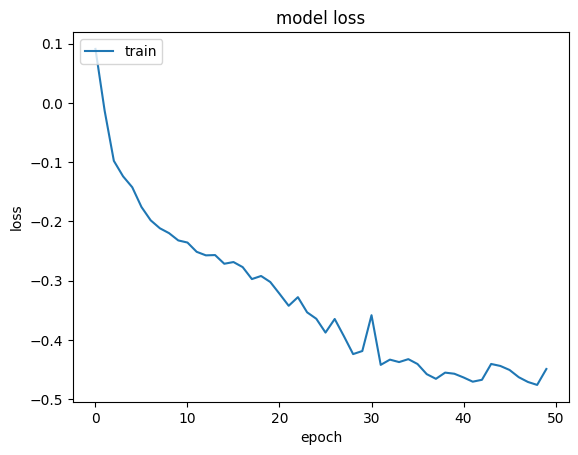

In [5]:
WINDOW_LEN  = 128
OPTIMIZER   = tf.keras.optimizers.Adam(learning_rate=0.0001)
LOSS        = tf.keras.losses.MeanAbsoluteError()
model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics=['mae'])
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

train_ds = tf.data.Dataset.from_tensor_slices(((seqEffData, seqCycleData, seqManiData), seqEffData))
train_ds = train_ds.batch(32).shuffle(buffer_size=seqEffData.shape[0])

history = model.fit(train_ds, epochs=50, verbose=1)

plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train"],loc ="upper left")


In [6]:
print("Saving the model ...............")
model.save('ckpt/VAEConstrains/my_model.h5')  # Save as an HDF5 file

model       = keras.models.load_model('ckpt/VAEConstrains/my_model.h5', custom_objects={'C_constraint': C_constraint})
# Show the model architecture
model.summary()
print("load model successfully")

Saving the model ...............
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 InpX (InputLayer)              [(None, 128, 9)]     0           []                               
                                                                                                  
 conv1d (Conv1D)                (None, 128, 128)     98048       ['InpX[0][0]']                   
                                                                                                  
 conv1d_1 (Conv1D)              (None, 128, 64)      696384      ['conv1d[0][0]']                 
                                                                                                  
 conv1d_2 (Conv1D)              (None, 128, 32)      174112      ['conv1d_1[0][0]']               
                                                             

2703/2703 [==============================] - 6s 2ms/step


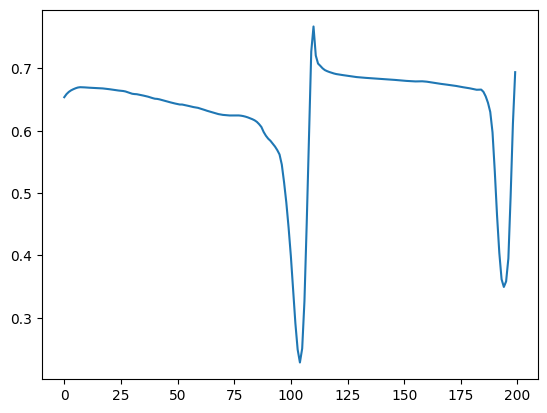

In [14]:
laten_extract = tf.keras.models.Model(inputs=model.inputs[0],
                                               outputs=[model.get_layer("Z").output])

z = laten_extract.predict(seqEffData, batch_size=32)
scaler = MinMaxScaler()
z = scaler.fit_transform(z.reshape(-1,1))
plt.plot(z[0:200], label = 'Predicted HI')
